# Przegląd wykorzystania OBV

## Co mamy?

W danych eventowych jest do wykorzystania 7 kolumn:
- obv_for_after
- obv_for_before
- obv_for_net
- obv_against_after
- obv_against_before
- obv_against_net
- obv_total_net

In [1]:
from get_data.get_data import get_merged_events
from sequences.which_sector import *
from sequences.get_sequences import *
from sequences.get_sequences import get_sequence_location
import pandas as pd

# match = 3836192 # Lech vs Wisła Płock
match = 3836322 # Jagiellonia vs Lech
def_areas_x = 12
def_areas_y = 8

events_types_to_analize = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'duels', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

events = get_merged_events(events_types_to_analize, match)

In [2]:
from dataframe_modify.generalize_perspective import generalize_perspective

events = generalize_perspective(events)

from dataframe_modify.grid_areas import add_areas_and_pos

events = add_areas_and_pos(events)

['Pass' 'Ball Receipt*' 'Carry' ... 'Foul Won' 'Half End' 'Half End']


In [3]:
from sequences.get_sequences import get_event_sequences

sequences = get_event_sequences(events)

seq = sequences[44]
seq = seq[seq['possession']==79]
seq.to_csv('single_sequence.csv', encoding='utf-8', index=False)
seq

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,off_camera,counterpress,out,start_x,start_y,end_x,end_y,start_area,end_area,area_code
1213,9f4488c8-37fc-4b0e-b08f-45cb6e69b9ae,1368,1,00:49:19.405,49,19,Pass,79,Lech Poznan,From Free Kick,...,True,,,31.1,67.0,43.9,17.0,D2,E7,D2E7
1214,1d3b55e8-b542-473e-b28f-97bfec473477,1369,1,00:49:22.137,49,22,Ball Receipt*,79,Lech Poznan,From Free Kick,...,,,,43.9,17.0,,,E7,,E7
1215,58245a31-7ed8-4af4-bf47-ad47ecdfacee,1370,1,00:49:22.766,49,22,Pass,79,Lech Poznan,From Free Kick,...,,,,50.5,16.0,71.1,2.6,F7,H8,F7H8
1216,cc08b0f1-79d0-441d-888e-e63ee4cf205b,1371,1,00:49:24.765,49,24,Ball Receipt*,79,Lech Poznan,From Free Kick,...,,,,71.1,2.6,,,H8,,H8
1217,593a67a0-7cb5-41f1-8dc2-dc93adf2ef42,1372,1,00:49:24.765,49,24,Carry,79,Lech Poznan,From Free Kick,...,,,,71.1,2.6,99.5,25.7,H8,J6,H8J6
1218,cfc9bc54-9cc6-48e3-98ae-7ca2664cac9d,1374,1,00:49:30.366,49,30,Dispossessed,79,Lech Poznan,From Free Kick,...,,,,99.5,25.7,,,J6,,J6
1219,cf882cc4-e040-4e76-81f9-aecee5745140,1375,1,00:49:30.366,49,30,Duel,79,Lech Poznan,From Free Kick,...,,,,99.4,25.6,,,J6,,J6
1220,9e3090c6-8ecf-4ee3-af2f-dc4a3195fe77,1376,1,00:49:31.419,49,31,Pass,79,Lech Poznan,From Free Kick,...,,,,97.5,28.9,85.9,28.5,J6,I6,J6I6
1221,144cedbe-5ceb-43c1-90b0-e0c3c0107414,1377,1,00:49:32.319,49,32,Ball Receipt*,79,Lech Poznan,From Free Kick,...,,,,85.9,28.5,,,I6,,I6
1222,4156fb7d-b076-40c2-a4a2-6dd8ead67791,1378,1,00:49:32.319,49,32,Carry,79,Lech Poznan,From Free Kick,...,,,,85.9,28.5,85.5,37.1,I6,I5,I6I5


## Przygotowanie wizualizacji

Team: Lech Poznan
1: Ľubomír Šatka (Pass) <00:49:19.405>
2: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:49:22.137>
2: Pedro Miguel Braga Rebocho (Pass) <00:49:22.766>
3: Michał Skóraś (Ball Receipt*) <00:49:24.765>
3: Michał Skóraś (Carry) <00:49:24.765>
3: Michał Skóraś (Dispossessed) <00:49:30.366>
4: Rui Filipe Cunha Correia (Duel) <00:49:30.366>
5: João Pedro Reis Amaral (Pass) <00:49:31.419>
6: Jesper Karlström (Ball Receipt*) <00:49:32.319>
6: Jesper Karlström (Carry) <00:49:32.319>
6: Jesper Karlström (Pass) <00:49:33.796>
7: Heorhii Tsitaishvili (Ball Receipt*) <00:49:35.307>
7: Heorhii Tsitaishvili (Carry) <00:49:35.307>
7: Heorhii Tsitaishvili (Pass) <00:49:37.358>
8: João Pedro Reis Amaral (Ball Receipt*) <00:49:38.814>
8: João Pedro Reis Amaral (Carry) <00:49:38.814>
8: João Pedro Reis Amaral (Pass) <00:49:39.460>
9: Pedro Miguel Braga Rebocho (Ball Receipt*) <00:49:40.916>
9: Pedro Miguel Braga Rebocho (Carry) <00:49:40.916>
9: Pedro Miguel Braga Rebocho (Pass) <00:49:4

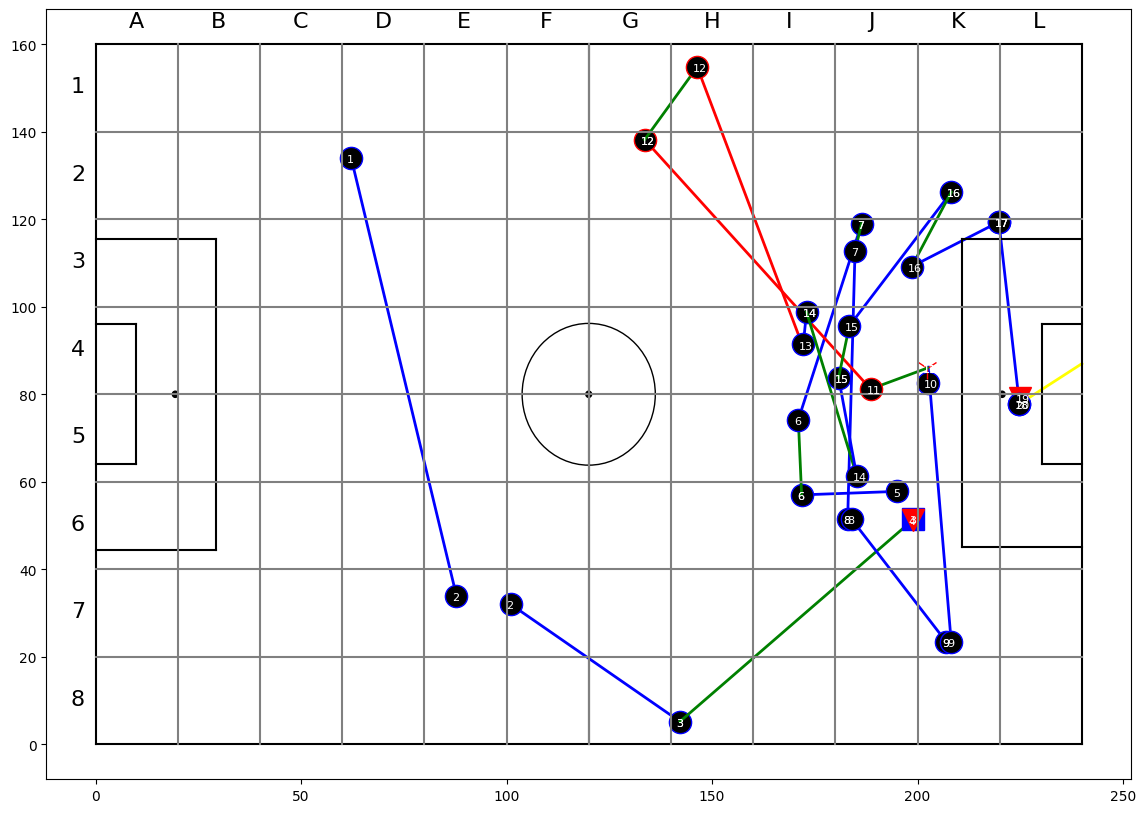

In [4]:
from draw.draw_sequences import draw_events_sequence

start_team ='Lech Poznan'
draw_events_sequence(seq, start_team, 12, 8, scale=2)
